# Task 7: Deep learning basics with PyTorch (reference solution)

This is the finished version of every worked example in `03_ml/notes/task7_ex*.md`, with its real outputs. **Type your own version first** in `03_ml/pytorch_basics.ipynb`, then use this file to compare or to get unstuck.

It runs from `03_ml/examples/`, so the paths start with `../` (the notes, written for `03_ml/`, don't have that). Its charts and model files go to the same `03_ml/output/` and `03_ml/models/` folders as yours, and they come out identical.

In [1]:
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

## Exercise 1: Tensors

In [2]:
print("PyTorch", torch.__version__)
t = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print(t)
print("shape:", t.shape, " dims:", t.ndim, " dtype:", t.dtype)
print("whole numbers:", torch.tensor([1, 2, 3]).dtype)

PyTorch 2.15.0+cpu
tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape: torch.Size([2, 3])  dims: 2  dtype: torch.float32
whole numbers: torch.int64


In [3]:
prices = np.array([326.0, 2401.0, 18823.0])
p = torch.tensor(prices, dtype=torch.float32)
print(prices.dtype, "→", p.dtype)
print(p)
print(p.numpy(), type(p.numpy()))

float64 → torch.float32
tensor([  326.,  2401., 18823.])
[  326.  2401. 18823.] <class 'numpy.ndarray'>


In [4]:
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([10.0, 20.0, 30.0])
print(a + b, a * b, a ** 2)
print(a.sum(), a.mean(), a.mean().item())

tensor([11., 22., 33.]) tensor([10., 40., 90.]) tensor([1., 4., 9.])
tensor(6.) tensor(2.) 2.0


In [5]:
X = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])  # 2 rows, 3 features
w = torch.tensor([[0.5], [-1.0], [2.0]])  # 1 weight per feature
bias = torch.tensor([1.0])
out = X @ w + bias
print(out)
print(X.shape, "@", w.shape, "→", out.shape)

tensor([[ 5.5000],
        [10.0000]])
torch.Size([2, 3]) @ torch.Size([3, 1]) → torch.Size([2, 1])


In [6]:
try:
    X @ torch.tensor([[1.0], [2.0]])
except RuntimeError as error:
    print("Shape error:", error)
try:
    X @ torch.tensor([[1.0], [2.0], [3.0]], dtype=torch.float64)
except RuntimeError as error:
    print("Type error:", error)

Shape error: mm: mat1 and mat2 shapes cannot be multiplied (2x3 and 2x1)
Type error: expected m1 and m2 to have the same dtype, but got: float != double


In [7]:
print(X.mean(dim=0))
print(X - X.mean(dim=0))
print(X * torch.tensor([1.0, 10.0, 100.0]))

tensor([2.5000, 3.5000, 4.5000])
tensor([[-1.5000, -1.5000, -1.5000],
        [ 1.5000,  1.5000,  1.5000]])
tensor([[  1.,  20., 300.],
        [  4.,  50., 600.]])


In [8]:
y = torch.arange(6.0)
print(y, y.shape)
print(y.reshape(2, 3))
col = y.reshape(-1, 1)
print(col.shape, col.squeeze(1).shape, X.T.shape)
print("(6, 1) minus (6,) gives", (col - y).shape)

tensor([0., 1., 2., 3., 4., 5.]) torch.Size([6])
tensor([[0., 1., 2.],
        [3., 4., 5.]])
torch.Size([6, 1]) torch.Size([6]) torch.Size([3, 2])
(6, 1) minus (6,) gives torch.Size([6, 6])


In [9]:
print("GPU available:", torch.cuda.is_available())
print("t lives on:", t.device)
k = torch.tensor(2.0, requires_grad=True)
print(k * 3)

GPU available: False
t lives on: cpu
tensor(6., grad_fn=<MulBackward0>)


## Exercise 1 answers
- **Tensor** = PyTorch's array: `shape`, `ndim`, `dtype`. Decimals default to **float32** (NumPy uses float64): half the memory and precise enough for neural networks.
- **NumPy ↔ PyTorch:** `torch.tensor(array, dtype=torch.float32)` copies in, `.numpy()` goes back. `.item()` turns a one-number tensor into a Python float.
- **`X @ w + bias`** is a linear model for every row at once. Shape rule: `(2, 3) @ (3, 1) → (2, 1)`.
- **2 common errors:** shapes that don't match (`2x3 and 2x1`), and mixing float32 with float64 (`float != double`).
- **Broadcasting** repeats a smaller tensor to fit (`X - X.mean(dim=0)`). Danger: `(6, 1) − (6,)` silently becomes `(6, 6)`, so keep targets as `(rows, 1)`.
- **Why tensors exist:** they run on GPUs, and they record how they were computed so PyTorch can compute gradients (`grad_fn`).

## Exercise 2: Autograd

In [10]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2
print(y)
y.backward()
print("dy/dx at x = 3:", x.grad)

tensor(9., grad_fn=<PowBackward0>)
dy/dx at x = 3: tensor(6.)


In [11]:
for nudge in [0.1, 0.01, 0.001]:
    growth = ((3 + nudge) ** 2 - 3 ** 2) / nudge
    print(f"x grows by {nudge}: y grows {growth:.3f}× as much")

x grows by 0.1: y grows 6.100× as much
x grows by 0.01: y grows 6.010× as much
x grows by 0.001: y grows 6.001× as much


In [12]:
w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)
x_point, y_true = 2.0, 7.0
pred = w * x_point + b
loss = (pred - y_true) ** 2
loss.backward()
print(f"prediction {pred.item()}, loss {loss.item()}")
print(f"dloss/dw = {w.grad.item()}, dloss/db = {b.grad.item()}")

prediction 2.0, loss 25.0
dloss/dw = -20.0, dloss/db = -10.0


In [13]:
lr = 0.01
with torch.no_grad():
    w -= lr * w.grad
    b -= lr * b.grad
new_loss = (w * x_point + b - y_true) ** 2
print(f"w = {w.item():.2f}, b = {b.item():.2f}")
print(f"loss {loss.item():.2f} → {new_loss.item():.2f}")

w = 1.20, b = 0.10
loss 25.00 → 20.25


In [14]:
x = torch.tensor(3.0, requires_grad=True)
for _ in range(3):
    (x ** 2).backward()
    print("x.grad:", x.grad.item())
x.grad.zero_()
print("after zero_():", x.grad.item())

x.grad: 6.0
x.grad: 12.0
x.grad: 18.0
after zero_(): 0.0


In [15]:
for lr in [0.01, 0.1, 1.1]:
    x = torch.tensor(3.0, requires_grad=True)
    for _ in range(10):
        loss = x ** 2
        loss.backward()
        with torch.no_grad():
            x -= lr * x.grad
        x.grad.zero_()
    print(f"lr {lr}: x after 10 steps = {x.item():.3f}")

lr 0.01: x after 10 steps = 2.451
lr 0.1: x after 10 steps = 0.322
lr 1.1: x after 10 steps = 18.575


## Exercise 2 answers
- **Gradient** = how much the output changes when you nudge an input a tiny bit, and in which direction. The gradient of x² at x = 3 is **6** (nudging by 0.001 gives 6.001).
- **Autograd:** `requires_grad=True` records the operations (`grad_fn`), `.backward()` fills `.grad` for every tensor that needs it, from one backward pass.
- **Tiny model:** w = 1, b = 0 predicts 2 for a target of 7, so the loss is 25. Gradients −20 (w) and −10 (b): increase both.
- **Gradient descent:** `w -= lr * w.grad` inside `torch.no_grad()`. One step with lr 0.01: w 1 → 1.2, b 0 → 0.1, loss 25 → 20.25.
- **Gradients add up**, so reset them every step (`.grad.zero_()`).
- **Learning rate:** 0.01 is too slow (2.451), 0.1 works (0.322), 1.1 diverges (18.575).

## Exercise 3: A training loop by hand

In [16]:
df = pd.read_csv("../data/diamonds.csv")
features = ["carat", "cut", "color", "clarity", "depth", "table"]
X_train, X_test, y_train, y_test = train_test_split(
    df[features], df["price"], test_size=0.2, random_state=42
)
log_carat = torch.tensor(np.log(X_train["carat"].to_numpy()), dtype=torch.float32)
log_carat = log_carat.reshape(-1, 1)
log_price = torch.tensor(np.log(y_train.to_numpy()), dtype=torch.float32)
log_price = log_price.reshape(-1, 1)
print(log_carat.shape, log_price.shape)
print("first 3 log carats:", log_carat[:3].squeeze(1))
print("first 3 log prices:", log_price[:3].squeeze(1))

torch.Size([43152, 1]) torch.Size([43152, 1])


first 3 log carats: tensor([0.6981, 0.0100, 0.0953])
first 3 log prices: tensor([9.6947, 8.4207, 8.6533])


In [17]:
line = LinearRegression().fit(log_carat.numpy(), log_price.numpy())
slope, intercept = line.coef_[0][0], line.intercept_[0]
print(f"scikit-learn: slope {slope:.4f}, intercept {intercept:.4f}")

scikit-learn: slope 1.6780, intercept 8.4502


In [18]:
torch.manual_seed(42)
w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
lr = 0.1
for step in range(301):
    pred = log_carat * w + b  # 1. forward: predict every diamond
    loss = ((pred - log_price) ** 2).mean()  # 2. loss: mean squared error
    if step % 50 == 0:
        print(f"step {step:3d}   loss {loss.item():8.4f}   "
              f"w {w.item():.4f}   b {b.item():.4f}")
    loss.backward()  # 3. backward: compute the gradients
    with torch.no_grad():  # 4. update: one step downhill
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()  # 5. reset the gradients for the next step
    b.grad.zero_()

step   0   loss  61.4110   w 0.3367   b 0.1288
step  50   loss   0.0925   w 1.4247   b 8.3115
step 100   loss   0.0692   w 1.6638   b 8.4424
step 150   loss   0.0692   w 1.6772   b 8.4497
step 200   loss   0.0692   w 1.6779   b 8.4502


step 250   loss   0.0692   w 1.6780   b 8.4502
step 300   loss   0.0692   w 1.6780   b 8.4502


In [19]:
print(f"PyTorch:      slope {w.item():.4f}, intercept {b.item():.4f}")
print(f"scikit-learn: slope {slope:.4f}, intercept {intercept:.4f}")
test_log_carat = torch.tensor(np.log(X_test["carat"].to_numpy()), dtype=torch.float32)
with torch.no_grad():
    test_pred = torch.exp(test_log_carat.reshape(-1, 1) * w + b).squeeze(1)
print(f"Test MAE: ${mean_absolute_error(y_test, test_pred.numpy()):,.0f}")
print(f"Twice the carat → {2 ** w.item():.1f}× the price")

PyTorch:      slope 1.6780, intercept 8.4502
scikit-learn: slope 1.6780, intercept 8.4502
Test MAE: $839
Twice the carat → 3.2× the price


## Exercise 3 answers
- **Data:** log carat and log price of the 43,152 training diamonds (Task 6 split), as float32 tensors of shape `(43152, 1)`.
- **The 5 steps:** forward (`log_carat * w + b`) → loss (mean squared error) → `backward()` → update inside `torch.no_grad()` → reset the gradients. Seed 42, learning rate 0.1, 300 steps.
- **Loss:** 61.4 at step 0 (random start), **0.0692** from step 100; `w` and `b` settle by step 250.
- **Result:** slope **1.6780**, intercept **8.4502**, the same as `LinearRegression` to 4 decimals.
- **Test MAE $839** with carat only (Task 6's plain line: $1,010). Twice the carat = 3.2× the price.

## Exercise 4: A neural network for diamond prices

In [20]:
def to_tensor(array):
    return torch.tensor(array, dtype=torch.float32)


def log_target(prices):
    return to_tensor(np.log(prices.to_numpy())).reshape(-1, 1)


X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)
log_then_scale = Pipeline([
    ("log", FunctionTransformer(np.log)),
    ("scale", StandardScaler()),
])
diamond_prep = ColumnTransformer([
    ("carat", log_then_scale, ["carat"]),
    ("num", StandardScaler(), ["depth", "table"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     ["cut", "color", "clarity"]),
])
X_fit_t = to_tensor(diamond_prep.fit_transform(X_fit))
X_val_t = to_tensor(diamond_prep.transform(X_val))
X_test_t = to_tensor(diamond_prep.transform(X_test))
y_fit_t, y_val_t = log_target(y_fit), log_target(y_val)
print("fit:", X_fit_t.shape, " validation:", X_val_t.shape, " test:", X_test_t.shape)
print(X_fit_t[0])

fit: torch.Size([34521, 23])  validation: torch.Size([8631, 23])  test: torch.Size([10788, 23])
tensor([ 0.9249, -0.6594,  3.3801,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000])


In [21]:
class PriceNet(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.layers(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


torch.manual_seed(42)
untrained = PriceNet(X_fit_t.shape[1])
print(untrained)
print("Parameters:", count_params(untrained))
print("Untrained predictions:", untrained(X_fit_t[:3]).squeeze(1))

PriceNet(
  (layers): Sequential(
    (0): Linear(in_features=23, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parameters: 3649


Untrained predictions: tensor([0.2311, 0.1675, 0.2198], grad_fn=<SqueezeBackward1>)


In [22]:
fit_data = TensorDataset(X_fit_t, y_fit_t)
print("rows:", len(fit_data))
loader = DataLoader(fit_data, batch_size=256, shuffle=True,
                    generator=torch.Generator().manual_seed(42))
xb, yb = next(iter(loader))
print("one batch:", xb.shape, yb.shape, " batches per epoch:", len(loader))

rows: 34521


one batch: torch.Size([256, 23]) torch.Size([256, 1])  batches per epoch: 135


In [23]:
torch.manual_seed(42)
price_net = PriceNet(X_fit_t.shape[1])
optimizer = torch.optim.Adam(price_net.parameters(), lr=0.001)
loss_fn = nn.MSELoss()
loader = DataLoader(fit_data, batch_size=256, shuffle=True,
                    generator=torch.Generator().manual_seed(42))
history = []
start = time.perf_counter()
for epoch in range(1, 31):
    price_net.train()
    epoch_loss = 0.0
    for xb, yb in loader:
        loss = loss_fn(price_net(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(xb)
    price_net.eval()
    with torch.no_grad():
        val_loss = loss_fn(price_net(X_val_t), y_val_t).item()
    history.append({"epoch": epoch, "train": epoch_loss / len(fit_data),
                    "validation": val_loss})
    if epoch in (1, 2, 5) or epoch % 10 == 0:
        print(f"epoch {epoch:2d}   train loss {history[-1]['train']:.4f}   "
              f"validation loss {val_loss:.4f}")
print(f"PriceNet trained in {time.perf_counter() - start:.1f} s")

epoch  1   train loss 19.4013   validation loss 0.2481
epoch  2   train loss 0.1588   validation loss 0.0929


epoch  5   train loss 0.0402   validation loss 0.0304


epoch 10   train loss 0.0184   validation loss 0.0174


epoch 20   train loss 0.0138   validation loss 0.0142


epoch 30   train loss 0.0128   validation loss 0.0134
PriceNet trained in 10.6 s


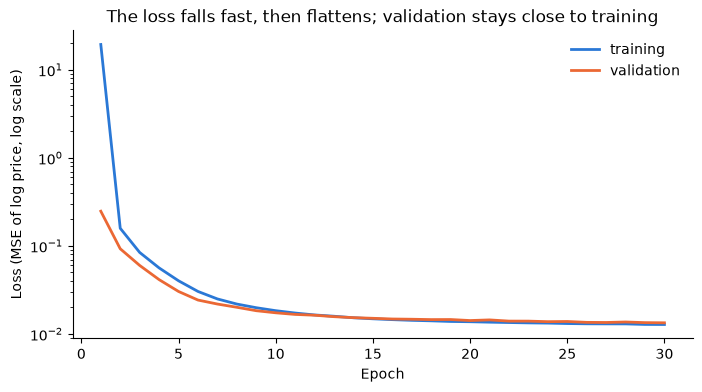

In [24]:
output_dir = Path("../output")
output_dir.mkdir(exist_ok=True)
curves = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curves["epoch"], curves["train"], color="#2a78d6", linewidth=2,
        label="training")
ax.plot(curves["epoch"], curves["validation"], color="#eb6834", linewidth=2,
        label="validation")
ax.set(yscale="log", xlabel="Epoch", ylabel="Loss (MSE of log price, log scale)",
       title="The loss falls fast, then flattens; validation stays close to training")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(output_dir / "loss_curve.png", bbox_inches="tight")
plt.show()

In [25]:
price_net.eval()
with torch.no_grad():
    net_pred = torch.exp(price_net(X_test_t)).squeeze(1).numpy()
print(f"Neural net test MAE: ${mean_absolute_error(y_test, net_pred):,.0f}")

Neural net test MAE: $336


## Exercise 4 answers
- **Data:** scikit-learn's `ColumnTransformer` (log + scale carat, scale depth and table, one-hot grades with `sparse_output=False`) → 23 float32 columns. Fit / validation / test = 34,521 / 8,631 / 10,788 rows.
- **Model:** `PriceNet(nn.Module)`: Linear 23 → 64, ReLU, Linear 64 → 32, ReLU, Linear 32 → 1. **3,649 parameters.** ReLU is what lets it learn curves.
- **Training:** `DataLoader` batches of 256 (135 per epoch, shuffle seeded), Adam lr 0.001, `MSELoss`, 30 epochs in about 10 s. Loss: train 19.4 → 0.0128, validation 0.248 → 0.0134 (about ±12% of the price).
- **Loss curves:** both fall fast and then flatten; validation stays close to training, so no overfitting.
- **Test MAE $336**: better than every linear model ($400 on log scales), worse than tuned gradient boosting ($285). On tables, boosting usually wins.

## Exercise 5: Titanic survival with a neural network

In [26]:
titanic = pd.read_csv("../../02_data/data/titanic.csv")
numeric = ["pclass", "age", "sibsp", "parch", "fare"]
categorical = ["sex", "embarked"]
X_train, X_test, y_train, y_test = train_test_split(
    titanic[numeric + categorical], titanic["survived"],
    test_size=0.2, random_state=42, stratify=titanic["survived"],
)
titanic_prep = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical),
])
X_train_t = to_tensor(titanic_prep.fit_transform(X_train))
X_test_t = to_tensor(titanic_prep.transform(X_test))
y_train_t = to_tensor(y_train.to_numpy()).reshape(-1, 1)
y_test_t = to_tensor(y_test.to_numpy()).reshape(-1, 1)
print("train:", X_train_t.shape, " test:", X_test_t.shape)
print(f"survival rate: train {y_train_t.mean():.1%}, test {y_test_t.mean():.1%}")

train: torch.Size([712, 10])  test: torch.Size([179, 10])
survival rate: train 38.3%, test 38.5%


In [27]:
logits = torch.tensor([-3.0, 0.0, 2.0])
print("logits:       ", logits)
print("probabilities:", torch.sigmoid(logits))
print("predictions:  ", (torch.sigmoid(logits) >= 0.5).int())

logits:        tensor([-3.,  0.,  2.])
probabilities: tensor([0.0474, 0.5000, 0.8808])
predictions:   tensor([0, 1, 1], dtype=torch.int32)


In [28]:
def accuracy(net, X_t, y_t):
    with torch.no_grad():
        predictions = (torch.sigmoid(net(X_t)) >= 0.5).float()
    return (predictions == y_t).float().mean().item()


def train_survival_net(seed, epochs=50, verbose=False):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(X_train_t.shape[1], 16), nn.ReLU(), nn.Linear(16, 1))
    optimizer = torch.optim.Adam(net.parameters(), lr=0.001)
    loss_fn = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32,
                        shuffle=True, generator=torch.Generator().manual_seed(seed))
    for epoch in range(1, epochs + 1):
        net.train()
        for xb, yb in loader:
            loss = loss_fn(net(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        net.eval()
        if verbose and epoch % 10 == 0:
            with torch.no_grad():
                train_loss = loss_fn(net(X_train_t), y_train_t).item()
            print(f"epoch {epoch}   train loss {train_loss:.4f}   "
                  f"train accuracy {accuracy(net, X_train_t, y_train_t):.1%}")
    return net


survival_net = train_survival_net(seed=42, verbose=True)

epoch 10   train loss 0.5012   train accuracy 77.8%


epoch 20   train loss 0.4271   train accuracy 82.9%


epoch 30   train loss 0.4100   train accuracy 82.4%


epoch 40   train loss 0.4009   train accuracy 82.9%


epoch 50   train loss 0.3947   train accuracy 83.8%


In [29]:
with torch.no_grad():
    test_proba = torch.sigmoid(survival_net(X_test_t)).squeeze(1)
print("first 5 chances:", test_proba[:5].numpy().round(2))
print("first 5 actual: ", y_test_t[:5].squeeze(1).int().numpy())
test_acc = accuracy(survival_net, X_test_t, y_test_t)
correct = round(test_acc * len(y_test_t))
print(f"Test accuracy: {test_acc:.1%} ({correct} of {len(y_test_t)} passengers)")

first 5 chances: [0.09 0.09 0.19 0.05 0.68]
first 5 actual:  [0 0 1 0 1]
Test accuracy: 79.3% (142 of 179 passengers)


In [30]:
rows = []
for seed in range(5):
    net = train_survival_net(seed)
    rows.append({"seed": seed,
                 "train": accuracy(net, X_train_t, y_train_t),
                 "test": accuracy(net, X_test_t, y_test_t)})
display(pd.DataFrame(rows).set_index("seed").round(3))

,train,test
seed,,
0,0.824,0.816
1,0.838,0.816
2,0.837,0.810
3,0.834,0.821
4,0.822,0.827


## Exercise 5 answers
- **Data:** Task 5's split (712 / 179, stratified) and cleaning (median + scale, most frequent + one-hot) → 10 float32 columns. Targets are 0.0 / 1.0 floats, shape `(712, 1)`.
- **Model:** Linear 10 → 16, ReLU, Linear 16 → 1 (a **logit**). `BCEWithLogitsLoss` applies the sigmoid inside; `torch.sigmoid` gives probabilities; ≥ 0.5 means "survived".
- **Result (seed 42):** train accuracy 83.8%, **test 79.3%** (142 of 179). Logistic regression got 80.4% (144) and the tuned forest 79.9% (143): too close to call.
- **Seeds 0–4:** test accuracy from 81.0% to 82.7%, from luck alone. The average of all 6 runs is 81.4%.
- **Lesson:** on small tables, deep learning adds code, settings and seed luck, but no clear accuracy gain. Use logistic regression or trees first.

## Exercise 6: Save, load, predict, and when to use deep learning

In [31]:
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)
for name, weights in price_net.state_dict().items():
    print(f"{name:17} {tuple(weights.shape)}")
net_path = models_dir / "diamond_price_net.pt"
prep_path = models_dir / "diamond_price_net_prep.joblib"
torch.save(price_net.state_dict(), net_path)
joblib.dump(diamond_prep, prep_path)
for path in [net_path, prep_path]:
    print(f"Saved {path.name} ({path.stat().st_size / 1024:.0f} KB)")

layers.0.weight   (64, 23)
layers.0.bias     (64,)
layers.2.weight   (32, 64)
layers.2.bias     (32,)
layers.4.weight   (1, 32)
layers.4.bias     (1,)
Saved diamond_price_net.pt (17 KB)
Saved diamond_price_net_prep.joblib (4 KB)


In [32]:
loaded_net = PriceNet(n_features=23)
print(loaded_net.load_state_dict(torch.load(net_path, weights_only=True)))
loaded_net.eval()
loaded_prep = joblib.load(prep_path)

<All keys matched successfully>


In [33]:
new_diamonds = pd.DataFrame([
    {"carat": 0.5, "cut": "Ideal", "color": "E", "clarity": "VS1",
     "depth": 61.5, "table": 56.0},
    {"carat": 1.0, "cut": "Premium", "color": "G", "clarity": "SI1",
     "depth": 62.0, "table": 58.0},
    {"carat": 2.0, "cut": "Good", "color": "J", "clarity": "I1",
     "depth": 63.0, "table": 59.0},
])
new_t = to_tensor(loaded_prep.transform(new_diamonds))
with torch.no_grad():
    log_prices = loaded_net(new_t)
    print("Same as before saving:", torch.equal(log_prices, price_net(new_t)))
boosting = joblib.load(models_dir / "diamond_price_model.joblib")
display(new_diamonds.assign(
    neural_net=torch.exp(log_prices).squeeze(1).numpy().round(0),
    boosting=boosting.predict(new_diamonds).round(0),
))

Same as before saving: True


,carat,cut,color,clarity,depth,table,neural_net,boosting
0,0.5,Ideal,E,VS1,61.5,56.0,1687.0,1773.0
1,1.0,Premium,G,SI1,62.0,58.0,4638.0,4588.0
2,2.0,Good,J,I1,63.0,59.0,6079.0,6713.0


In [34]:
block = nn.TransformerEncoderLayer(d_model=768, nhead=12, dim_feedforward=3072)
tokens = nn.Embedding(50257, 768)
positions = nn.Embedding(1024, 768)
final_norm = nn.LayerNorm(768)
gpt2_small = (count_params(tokens) + count_params(positions)
              + 12 * count_params(block) + count_params(final_norm))
print(f"PriceNet:              {count_params(price_net):>11,} parameters")
print(f"One transformer block: {count_params(block):>11,} parameters")
print(f"GPT-2 small:           {gpt2_small:>11,} parameters, "
      f"{gpt2_small * 4 / 1e6:,.0f} MB as float32")

PriceNet:                    3,649 parameters
One transformer block:   7,087,872 parameters
GPT-2 small:           124,439,808 parameters, 498 MB as float32


## Exercise 6 answers
- **Saved:** `price_net.state_dict()` (6 tensors) with `torch.save` → `models/diamond_price_net.pt` (17 KB), plus the `ColumnTransformer` with `joblib` (the network is useless without it).
- **Loaded:** a fresh `PriceNet(23)` + `load_state_dict(torch.load(..., weights_only=True))` → `<All keys matched successfully>`, then `eval()`. Its predictions are identical (`torch.equal`).
- **3 new diamonds:** network **$1,687 / $4,638 / $6,079**; boosting $1,773 / $4,588 / $6,713.
- **Scale:** PriceNet has 3,649 parameters; GPT-2 small has **124,439,808** (about 500 MB). An LLM is a huge `nn.Module` built from the same parts.
- **When to use deep learning:** images, text, audio and very large data sets, usually starting from a pretrained model. For tables, use gradient boosting or logistic regression first.